In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# How do I connect a scalar input to the ODE?

By default, we recommend that users treat all ODE input variables as if they are _potentially_ dynamic.
This allows the user to use the input as either a dynamic control, or as a static design or input parameter.
By default, parameters will "fan" the value out to all nodes.
This allows the partials to be defined in a consistent fashion (generally a diagonal matrix for a scalar input and output) regardless of whether the input is static or dynamic.

**But** there are some cases in which the user may know that a variable will never have the potential to change throughout the trajectory.
In these cases, we can reduce a bit of the data transfer OpenMDAO needs to perform by defining the input as a scalar in the ODE, rather than sizing it based on the number of nodes.

## The Brachistochrone with a static input.

The local gravity `g` in the brachistochrone problem makes a good candidate for a static input parameter.
The brachistochrone generally won't be in an environment where the local acceleration of gravity is varying by any significant amount.

In the slightly modified brachistochrone example below, we add a new option to the BrachistochroneODE `static_gravity` that allows us to decide whether gravity is a vectorized input or a scalar input to the ODE.

In [2]:
om.display_source("dymos.examples.brachistochrone.brachistochrone_ode")

import numpy as np
import openmdao.api as om


class BrachistochroneODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)
        self.options.declare('static_gravity', types=(bool,), default=False,
                             desc='If True, treat gravity as a static (scalar) input, rather than '
                                  'having different values at each node.')

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('v', val=np.zeros(nn), desc='velocity', units='m/s')

        if self.options['static_gravity']:
            self.add_input('g', val=9.80665, desc='grav. acceleration', units='m/s/s',
                           tags=['dymos.static_target'])
        else:
            self.add_input('g', val=9.80665 * np.ones(nn), desc='grav. acceleration', units='m/s/s')

        self.add_input('theta', val=np.ones(nn), desc='angle of wire', units='rad')

        self.add_output('xdot', val=np.zeros(nn), desc='velocity component in x', units='m/s',
                        tags=['dymos.state_rate_source:x', 'dymos.state_units:m'])

        self.add_output('ydot', val=np.zeros(nn), desc='velocity component in y', units='m/s',
                        tags=['dymos.state_rate_source:y', 'dymos.state_units:m'])

        self.add_output('vdot', val=np.zeros(nn), desc='acceleration magnitude', units='m/s**2',
                        tags=['dymos.state_rate_source:v', 'dymos.state_units:m/s'])

        self.add_output('check', val=np.zeros(nn), desc='check solution: v/sin(theta) = constant',
                        units='m/s')

        # Setup partials
        arange = np.arange(self.options['num_nodes'])
        self.declare_partials(of='vdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='xdot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='xdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='ydot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='ydot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='check', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='check', wrt='theta', rows=arange, cols=arange)

        if self.options['static_gravity']:
            c = np.zeros(self.options['num_nodes'])
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=c)
        else:
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=arange)

    def compute(self, inputs, outputs):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        outputs['vdot'] = g * cos_theta
        outputs['xdot'] = v * sin_theta
        outputs['ydot'] = -v * cos_theta
        outputs['check'] = v / sin_theta

    def compute_partials(self, inputs, partials):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        partials['vdot', 'g'] = cos_theta
        partials['vdot', 'theta'] = -g * sin_theta

        partials['xdot', 'v'] = sin_theta
        partials['xdot', 'theta'] = v * cos_theta

        partials['ydot', 'v'] = -cos_theta
        partials['ydot', 'theta'] = v * sin_theta

        partials['check', 'v'] = 1 / sin_theta
        partials['check', 'theta'] = -v * cos_theta / sin_theta ** 2

In the corresponding run script, we pass `{'static_gravity': True}` as one of the `ode_init_kwargs` to the Phase, and declare $g$ as a static design variable using the `dynamic=False` argument.

In [3]:
%matplotlib inline


Jacobian shape: (40, 50)  (13.40% nonzero)
FWD solves: 8   REV solves: 0
Total colors vs. total size: 8 vs 50  (84.00% improvement)

Sparsity computed using tolerance: 1e-25.
Dense total jacobian for Problem 'connect_scalar_parameters_to_ode' was computed 3 times.
Time to compute sparsity:   0.1853 sec
Time to compute coloring:   0.0800 sec
Memory to compute coloring:   0.4336 MB
Coloring created on: 2026-10-16 15:46:48


Optimization terminated successfully    (Exit mode 0)
            Current function value: 18.016167304638337
            Iterations: 24
            Function evaluations: 24
            Gradient evaluations: 24
Optimization Complete
-----------------------------------



Simulating trajectory traj


Done simulating trajectory traj


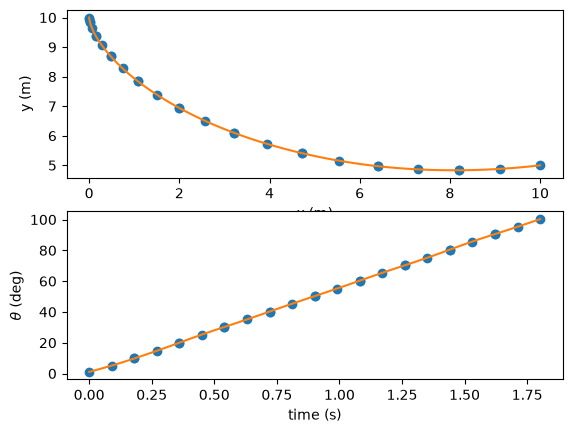

In [4]:
import openmdao.api as om
import dymos as dm
import matplotlib.pyplot as plt
from dymos.examples.brachistochrone.brachistochrone_ode import BrachistochroneODE

#
# Initialize the Problem and the optimization driver
#
p = om.Problem(model=om.Group())
p.driver = om.ScipyOptimizeDriver()
p.driver.declare_coloring()

#
# Create a trajectory and add a phase to it
#
traj = p.model.add_subsystem('traj', dm.Trajectory())

phase = traj.add_phase('phase0',
                       dm.Phase(ode_class=BrachistochroneODE,
                                ode_init_kwargs={'static_gravity': True},
                                transcription=dm.GaussLobatto(num_segments=10)))

#
# Set the variables
#
phase.set_time_options(fix_initial=True, duration_bounds=(.5, 10))

phase.add_state('x', rate_source='xdot',
                targets=None,
                units='m',
                fix_initial=True, fix_final=True, solve_segments=False)

phase.add_state('y', rate_source='ydot',
                targets=None,
                units='m',
                fix_initial=True, fix_final=True, solve_segments=False)

phase.add_state('v', rate_source='vdot',
                targets=['v'],
                units='m/s',
                fix_initial=True, fix_final=False, solve_segments=False)

phase.add_control('theta', targets=['theta'],
                  continuity=True, rate_continuity=True,
                  units='deg', lower=0.01, upper=179.9)

phase.add_parameter('g', targets=['g'], static_target=True, opt=False)

#
# Minimize time at the end of the phase
#
phase.add_objective('time', loc='final', scaler=10)

#
# Setup the Problem
#
p.setup()

#
# Set the initial values
# The initial time is fixed, and we set that fixed value here.
# The optimizer is allowed to modify t_duration, but an initial guess is provided here.
#
phase.set_time_val(initial=0.0, duration=2.0)

# Guesses for states are provided at all state_input nodes.
# We use the phase.interpolate method to linearly interpolate values onto the state input nodes.
# Since fix_initial=True for all states and fix_final=True for x and y, the initial or final
# values of the interpolation provided here will not be changed by the optimizer.
phase.set_state_val('x', [0, 10])
phase.set_state_val('y', [10, 5])
phase.set_state_val('v', [0, 9.9])

# Guesses for controls are provided at all control_input node.
# Here phase.interpolate is used to linearly interpolate values onto the control input nodes.
phase.set_control_val('theta', [5, 100.5])

# Set the value for gravitational acceleration.
phase.set_parameter_val('g', 9.80665)

#
# Solve for the optimal trajectory
#
dm.run_problem(p, simulate=True)

# Generate the explicitly simulated trajectory
sim_prob_dir = traj.sim_prob.get_outputs_dir()
exp_out = om.CaseReader(sim_prob_dir / 'dymos_simulation.db').get_case('final')

# Extract the timeseries from the implicit solution and the explicit simulation
x = p.get_val('traj.phase0.timeseries.x')
y = p.get_val('traj.phase0.timeseries.y')
t = p.get_val('traj.phase0.timeseries.time')
theta = p.get_val('traj.phase0.timeseries.theta')

x_exp = exp_out.get_val('traj.phase0.timeseries.x')
y_exp = exp_out.get_val('traj.phase0.timeseries.y')
t_exp = exp_out.get_val('traj.phase0.timeseries.time')
theta_exp = exp_out.get_val('traj.phase0.timeseries.theta')

fig, axes = plt.subplots(nrows=2, ncols=1)

axes[0].plot(x, y, 'o')
axes[0].plot(x_exp, y_exp, '-')
axes[0].set_xlabel('x (m)')
axes[0].set_ylabel('y (m)')

axes[1].plot(t, theta, 'o')
axes[1].plot(t_exp, theta_exp, '-')
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel(r'$\theta$ (deg)')

plt.show()

In [5]:
from openmdao.utils.assert_utils import assert_near_equal

# Test the results
assert_near_equal(p.get_val('traj.phase0.timeseries.time')[-1], 1.8016,
                  tolerance=1.0E-3)

np.float64(9.286447509678318e-06)